# Confidence Intervals for VaR: Unknown Volatility and Unknown Mean
## Apple, 11/01/2016–10/31/2018, one-day 97% VaR of a \$1,000,000 position

A \$1,000,000 position in Apple is held over 10/31/2018–11/01/2018. The daily log
returns are modelled as $X_{t+\Delta}\mid\mathcal F_t\sim N(\mu,\sigma^2)$ with unknown true
$\mu,\sigma$. From the $n$ daily log returns of 11/01/2016–10/31/2018 this notebook estimates
the one-day $\mathrm{VaR}_{0.97}$ of the full loss (i) from the empirical distribution and
(ii) from the normal formula with the sample mean and variance, and then measures the
uncertainty that comes from estimating the parameters: (a) a $98\%$ confidence interval when
$\mu$ is known and only $\sigma$ is estimated, using the chi-square distribution of the
sample variance, and (b) the simulation of lecture 9 for unknown $\mu$ and $\sigma$, with
$M=125{,}000$ trials.

**Formulas (lecture 9, slides 21–30).** Full loss $L=-V\bigl(e^{X}-1\bigr)$, so for
$X\sim N(\mu,\sigma^2)$

$$\mathrm{VaR}_\alpha(L)=V\Bigl(1-e^{\mu+\sigma\Phi^{-1}(1-\alpha)}\Bigr)=V\Bigl(1-e^{\mu-\sigma\Phi^{-1}(\alpha)}\Bigr).\qquad(1)$$

With $\bar X_n=\frac1n\sum X_i$ and $S_n^2=\frac1{n-1}\sum(X_i-\bar X_n)^2$,
$(n-1)S_n^2/\sigma^2\sim\chi^2_{n-1}$. If $q_p$ is the $p$-quantile of $\chi^2_{n-1}$, then with
probability $1-\beta$

$$\underline\sigma_\beta:=\sqrt{\tfrac{n-1}{q_{1-\beta/2}}}\,S_n\le\sigma\le\overline\sigma_\beta:=\sqrt{\tfrac{n-1}{q_{\beta/2}}}\,S_n,
\qquad
V\Bigl(1-e^{\mu-\underline\sigma_\beta\Phi^{-1}(\alpha)}\Bigr)\le\mathrm{VaR}_\alpha\le V\Bigl(1-e^{\mu-\overline\sigma_\beta\Phi^{-1}(\alpha)}\Bigr).$$

For unknown $\mu$: for $m=1,\dots,M$ sample $\sigma^m$ from $(n-1)S_n^2/(\sigma^m)^2\sim\chi^2_{n-1}$,
then $\mu^m\sim N\bigl(\bar X_n,(\sigma^m)^2/n\bigr)$, and set $Y_m=V\bigl(1-e^{\mu^m+\sigma^m\Phi^{-1}(1-\alpha)}\bigr)$.

---
## 1. Imports

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm, chi2
import matplotlib
import matplotlib.pyplot as plt

print("python     ", sys.version.split()[0])
print("numpy      ", np.__version__)
print("pandas     ", pd.__version__)
print("scipy      ", scipy.__version__)
print("matplotlib ", matplotlib.__version__)

python      3.13.18
numpy       2.1.3
pandas      2.2.3
scipy       1.15.3
matplotlib  3.10.0


---
## 2. Parameters

| Symbol | Meaning | Value |
|---|---|---|
| — | stock | Apple (AAPL), daily closes |
| — | sample period | 11/01/2016 – 10/31/2018 |
| — | VaR horizon | 10/31/2018 → 11/01/2018 (one day) |
| $V$ | position | \$1,000,000 |
| $\alpha$ | VaR level | 0.97 |
| $\beta$ | confidence intervals are $100(1-\beta)\%$ | 0.02 |
| $M$ | simulation trials in (b) | 125,000 |

The seed is fixed, so re-running the notebook reproduces every number exactly.

In [2]:
TICKER    = "AAPL"
FIRST_DAY = "2016-11-01"
LAST_DAY  = "2018-10-31"
V_PORT    = 1_000_000.0
ALPHA     = 0.97
BETA      = 0.02
M_SIM     = 125_000
SEED      = 731

DATA_FILE = Path("aapl_prices.csv")
FIG1 = Path("var_ci_simulation.png")
FIG2 = Path("var_ci_sigma.png")

usd = lambda v: ("-" if v < 0 else "") + r"\$" + f"{abs(v):,.0f}"
C_A, C_B, C_EMP, C_INK, C_MUTE = "#2a78d6", "#e34948", "#eb6834", "#0b0b0b", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.labelsize": 11, "legend.frameon": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
})
Z_LO = norm.ppf(1 - ALPHA)          # Phi^-1(1 - alpha) < 0
print(f"alpha = {ALPHA}: Phi^-1(1 - alpha) = {Z_LO:.6f};  beta = {BETA};  M = {M_SIM:,};  seed = {SEED}")

alpha = 0.97: Phi^-1(1 - alpha) = -1.880794;  beta = 0.02;  M = 125,000;  seed = 731


---
## 3. Data

Daily **closing** prices of Apple from Yahoo Finance (`Close`, adjusted for splits but not
for dividends, as in the earlier homeworks). The prices are cached in `aapl_prices.csv`; the
file also holds the dividend-adjusted closes, used only for a robustness check.

### Pseudocode — data

```
1  if aapl_prices.csv exists: read it                        (no network access)
2  else: download daily AAPL closes on [11/01/2016, 10/31/2018] and save them
3  check: first date 11/01/2016, last date 10/31/2018, no gaps, no repeats
4  x_i <- ln(S_i / S_{i-1}),  i = 1 ... n
```

In [3]:
def download_prices(first, last):
    """Daily Close and Adj Close from Yahoo Finance (only used when the cache is missing)."""
    import yfinance as yf
    end = (pd.Timestamp(last) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    df = yf.download(TICKER, start=first, end=end, interval="1d", auto_adjust=False,
                     actions=False, progress=False, threads=False)
    if df is None or df.empty:
        raise RuntimeError("Yahoo Finance returned no data")
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df.index = pd.to_datetime(df.index).tz_localize(None).normalize()
    t = pd.DataFrame({TICKER: df["Close"].astype(float), f"{TICKER}_adj": df["Adj Close"].astype(float)})
    t.index.name = "Date"
    return t.loc[first:last]


if DATA_FILE.exists():
    raw = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True)
    print(f"read cached prices from {DATA_FILE}")
else:
    raw = download_prices(FIRST_DAY, LAST_DAY)
    raw.to_csv(DATA_FILE, float_format="%.6f")
    print(f"downloaded prices from Yahoo Finance and saved them to {DATA_FILE}")

prices = raw[TICKER]
assert str(prices.index[0].date()) == FIRST_DAY and str(prices.index[-1].date()) == LAST_DAY
assert raw.notna().all().all() and not raw.index.has_duplicates and raw.index.is_monotonic_increasing
print(f"{len(prices)} closes, {prices.index[0].date()} to {prices.index[-1].date()}")
print(pd.concat([prices.head(3), prices.tail(3)]).to_string(float_format=lambda v: f"{v:10.4f}"))

read cached prices from aapl_prices.csv
504 closes, 2016-11-01 to 2018-10-31
Date
2016-11-01      27.8725
2016-11-02      27.8975
2016-11-03      27.4575
2018-10-29      53.0600
2018-10-30      53.3250
2018-10-31      54.7150


---
## 4. Log returns and the standard estimators

In [4]:
X = np.log(prices).diff().dropna().to_numpy()
n = len(X)
XBAR = X.mean()
S2 = X.var(ddof=1)
S = np.sqrt(S2)
print(f"n = {n} daily log returns ({prices.index[1].date()} to {prices.index[-1].date()})")
print(f"sample mean      X_bar_n = {XBAR:.8f}")
print(f"sample variance  S_n^2   = {S2:.10f}")
print(f"sample sd        S_n     = {S:.8f}   ({S * np.sqrt(252):.2%} a year)")
print(f"skewness {pd.Series(X).skew():.3f},  excess kurtosis {pd.Series(X).kurt():.3f}  (normal: 0 and 0)")
print(f"largest daily loss {-V_PORT * np.expm1(X.min()):,.2f} on {prices.index[1 + X.argmin()].date()}"
      f"  ({(X.min() - XBAR) / S:.2f} sample standard deviations)")

n = 503 daily log returns (2016-11-02 to 2018-10-31)
sample mean      X_bar_n = 0.00134095
sample variance  S_n^2   = 0.0001679993
sample sd        S_n     = 0.01296145   (20.58% a year)
skewness 0.207,  excess kurtosis 2.918  (normal: 0 and 0)
largest daily loss 46,326.07 on 2018-10-10  (-3.76 sample standard deviations)


---
## 5. Part (a): VaR estimates and a confidence interval when $\mu$ is known

**Empirical.** The full losses $\ell_i=-V(e^{x_i}-1)$, sorted, give
$\widehat{\mathrm{VaR}}_\alpha=\ell_{(\lceil n\alpha\rceil)}$.

**Theoretical.** Formula (1) with $\mu=\bar X_n$ and $\sigma=S_n$.

**Confidence interval.** $\mu=\bar X_n$ is taken as known. Because
$\Phi^{-1}(1-\alpha)<0$, formula (1) is increasing in $\sigma$, so the $98\%$ interval
$[\underline\sigma_\beta,\overline\sigma_\beta]$ for $\sigma$ maps to the $98\%$ interval
$[\mathrm{VaR}(\underline\sigma_\beta),\mathrm{VaR}(\overline\sigma_\beta)]$ for the VaR.

### Pseudocode — part (a)

```
1  losses l_i <- -V (exp(x_i) - 1);  sort;  VaR_emp <- l_(ceil(n alpha))
2  VaR_th  <- V (1 - exp(X_bar + S_n Phi^-1(1 - alpha)))
3  q_lo <- chi2_{n-1} quantile at beta/2;   q_hi <- chi2_{n-1} quantile at 1 - beta/2
4  sigma_low  <- S_n sqrt((n - 1) / q_hi);   sigma_high <- S_n sqrt((n - 1) / q_lo)
5  CI_a <- [ V (1 - exp(X_bar + sigma_low  Phi^-1(1 - alpha))),
             V (1 - exp(X_bar + sigma_high Phi^-1(1 - alpha))) ]
```

In [5]:
def var_normal(mu, sigma, alpha=ALPHA, v=V_PORT):
    """Formula (1): VaR of the full loss -V(e^X - 1) for X ~ N(mu, sigma^2)."""
    return v * (1 - np.exp(mu + sigma * norm.ppf(1 - alpha)))


LOSS = -V_PORT * np.expm1(X)
J_EMP = int(np.ceil(n * ALPHA))
VAR_EMP = float(np.sort(LOSS)[J_EMP - 1])
VAR_TH = float(var_normal(XBAR, S))

Q_LO, Q_HI = chi2.ppf(BETA / 2, n - 1), chi2.ppf(1 - BETA / 2, n - 1)
SIG_LOW, SIG_HIGH = S * np.sqrt((n - 1) / Q_HI), S * np.sqrt((n - 1) / Q_LO)
CI_A = (float(var_normal(XBAR, SIG_LOW)), float(var_normal(XBAR, SIG_HIGH)))

print(f"(a1) empirical VaR_{ALPHA} = l_({J_EMP}) of {n} = {VAR_EMP:,.2f}")
print(f"(a2) theoretical VaR_{ALPHA} = V(1 - exp({XBAR:.6f} + {S:.6f} x ({Z_LO:.6f}))) = {VAR_TH:,.2f}")
print(f"\nchi-square, {n - 1} degrees of freedom: q_{BETA / 2:.2f} = {Q_LO:.4f},  q_{1 - BETA / 2:.2f} = {Q_HI:.4f}")
print(f"98% interval for sigma: [{SIG_LOW:.6f}, {SIG_HIGH:.6f}]   (S_n = {S:.6f})")
print(f"98% interval for VaR (mu known): [{CI_A[0]:,.2f}, {CI_A[1]:,.2f}]   width {CI_A[1] - CI_A[0]:,.2f}")
print(f"  relative to the point estimate: {CI_A[0] / VAR_TH - 1:+.2%} / {CI_A[1] / VAR_TH - 1:+.2%}")

(a1) empirical VaR_0.97 = l_(488) of 503 = 24,984.40
(a2) theoretical VaR_0.97 = V(1 - exp(0.001341 + 0.012961 x (-1.880794))) = 22,773.55

chi-square, 502 degrees of freedom: q_0.01 = 431.2405,  q_0.99 = 578.6398
98% interval for sigma: [0.012073, 0.013984]   (S_n = 0.012961)
98% interval for VaR (mu known): [21,138.54, 24,651.99]   width 3,513.46
  relative to the point estimate: -7.18% / +8.25%


---
## 6. Part (b): simulation for unknown $\mu$ and $\sigma$ (lecture 9, slide 30)

### Pseudocode — part (b)

```
INPUT : n, X_bar, S_n^2, alpha, beta, V, M, seed
1  for m = 1 ... M  (vectorised):
2        W_m     <- chi-square draw with n - 1 degrees of freedom
3        sigma_m <- sqrt( (n - 1) S_n^2 / W_m )          from (n-1) S_n^2 / sigma^2 ~ chi2_{n-1}
4        mu_m    <- X_bar + (sigma_m / sqrt(n)) Z_m,  Z_m ~ N(0,1)   (X_bar - mu)/(sigma/sqrt n) ~ N(0,1)
5        Y_m     <- V (1 - exp(mu_m + sigma_m Phi^-1(1 - alpha)))
6  Y_bar <- (1/M) sum Y_m
7  sort Y;   A <- Y_(ceil(M beta/2)),   B <- Y_(ceil(M (1 - beta/2)))
```

In [6]:
rng = np.random.default_rng(SEED)
W = rng.chisquare(n - 1, M_SIM)
SIG_M = np.sqrt((n - 1) * S2 / W)
MU_M = XBAR + SIG_M / np.sqrt(n) * rng.standard_normal(M_SIM)
Y = var_normal(MU_M, SIG_M)

Y_BAR = float(Y.mean())
Y_SE = float(Y.std(ddof=1) / np.sqrt(M_SIM))
Y_SORT = np.sort(Y)
J_A, J_B = int(np.ceil(M_SIM * BETA / 2)), int(np.ceil(M_SIM * (1 - BETA / 2)))
CI_B = (float(Y_SORT[J_A - 1]), float(Y_SORT[J_B - 1]))
print(f"Y_bar_M = {Y_BAR:,.2f}   (Monte-Carlo standard error {Y_SE:.2f})")
print(f"A = Y_({J_A:,}) = {CI_B[0]:,.2f},   B = Y_({J_B:,}) = {CI_B[1]:,.2f}   width {CI_B[1] - CI_B[0]:,.2f}")
print(f"  relative to Y_bar: {CI_B[0] / Y_BAR - 1:+.2%} / {CI_B[1] / Y_BAR - 1:+.2%}")
print(f"\nsimulated sigma_m: mean {SIG_M.mean():.6f}, 1% / 99% quantiles {np.quantile(SIG_M, 0.01):.6f} / "
      f"{np.quantile(SIG_M, 0.99):.6f}")
print(f"simulated mu_m:    mean {MU_M.mean():.6f}, sd {MU_M.std():.6f}  (S_n / sqrt(n) = {S / np.sqrt(n):.6f})")

Y_bar_M = 22,808.77   (Monte-Carlo standard error 2.67)
A = Y_(1,250) = 20,697.40,   B = Y_(123,750) = 25,091.16   width 4,393.76
  relative to Y_bar: -9.26% / +10.01%

simulated sigma_m: mean 0.012981, 1% / 99% quantiles 0.012071 / 0.013981
simulated mu_m:    mean 0.001340, sd 0.000581  (S_n / sqrt(n) = 0.000578)


---
## 7. Comparison

How much of the width in (b) comes from not knowing $\mu$? Re-running the same simulation
with $\mu^m=\bar X_n$ fixed isolates the $\sigma$ part, which should reproduce the
analytic interval of (a).

In [7]:
Y_SIG = var_normal(XBAR, SIG_M)                      # same sigma draws, mu fixed at X_bar
Ys = np.sort(Y_SIG)
CI_SIG_SIM = (float(Ys[J_A - 1]), float(Ys[J_B - 1]))
print(f"{'':<44}{'estimate':>12}{'98% low':>12}{'98% high':>12}{'width':>11}")
print(f"{'(a1) empirical distribution':<44}{VAR_EMP:>12,.2f}{'':>12}{'':>12}{'':>11}")
print(f"{'(a2) formula (1), X_bar and S_n; CI: mu known':<44}{VAR_TH:>12,.2f}{CI_A[0]:>12,.2f}{CI_A[1]:>12,.2f}"
      f"{CI_A[1] - CI_A[0]:>11,.2f}")
print(f"{'(b)  simulation, mu and sigma unknown':<44}{Y_BAR:>12,.2f}{CI_B[0]:>12,.2f}{CI_B[1]:>12,.2f}"
      f"{CI_B[1] - CI_B[0]:>11,.2f}")
print(f"{'     check: simulation with mu fixed':<44}{Y_SIG.mean():>12,.2f}{CI_SIG_SIM[0]:>12,.2f}"
      f"{CI_SIG_SIM[1]:>12,.2f}{CI_SIG_SIM[1] - CI_SIG_SIM[0]:>11,.2f}")
print(f"\nwidth (b) / width (a) = {(CI_B[1] - CI_B[0]) / (CI_A[1] - CI_A[0]):.3f}")
print(f"Y_bar - theoretical VaR = {Y_BAR - VAR_TH:+,.2f}")
print(f"empirical VaR inside the (a) interval: {CI_A[0] <= VAR_EMP <= CI_A[1]};  inside (b): {CI_B[0] <= VAR_EMP <= CI_B[1]}")
# sensitivity of the VaR to each parameter, one standard error each
dmu = S / np.sqrt(n); dsig = S / np.sqrt(2 * (n - 1))
print(f"\nVaR change for +1 s.e. in mu ({dmu:.6f}): {var_normal(XBAR + dmu, S) - VAR_TH:+,.2f};  "
      f"for +1 s.e. in sigma ({dsig:.6f}): {var_normal(XBAR, S + dsig) - VAR_TH:+,.2f}")
adj = np.log(raw[f"{TICKER}_adj"]).diff().dropna().to_numpy()
print(f"\ndividend-adjusted prices: X_bar {adj.mean():.6f}, S_n {adj.std(ddof=1):.6f}, "
      f"formula VaR {var_normal(adj.mean(), adj.std(ddof=1)):,.2f}")

                                                estimate     98% low    98% high      width
(a1) empirical distribution                    24,984.40                                   
(a2) formula (1), X_bar and S_n; CI: mu known   22,773.55   21,138.54   24,651.99   3,513.46
(b)  simulation, mu and sigma unknown          22,808.77   20,697.40   25,091.16   4,393.76
     check: simulation with mu fixed           22,808.37   21,136.09   24,645.18   3,509.09

width (b) / width (a) = 1.251
Y_bar - theoretical VaR = +35.22
empirical VaR inside the (a) interval: False;  inside (b): True

VaR change for +1 s.e. in mu (0.000578): -564.92;  for +1 s.e. in sigma (0.000409): +751.55

dividend-adjusted prices: X_bar 0.001406, S_n 0.012928, formula VaR 22,649.76


---
## 8. Figures

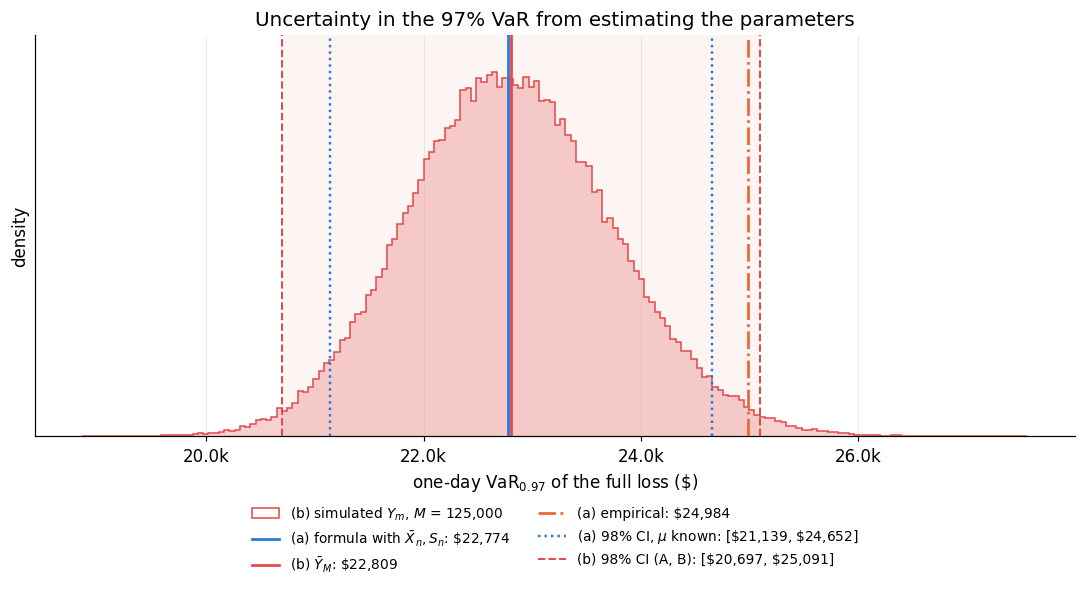

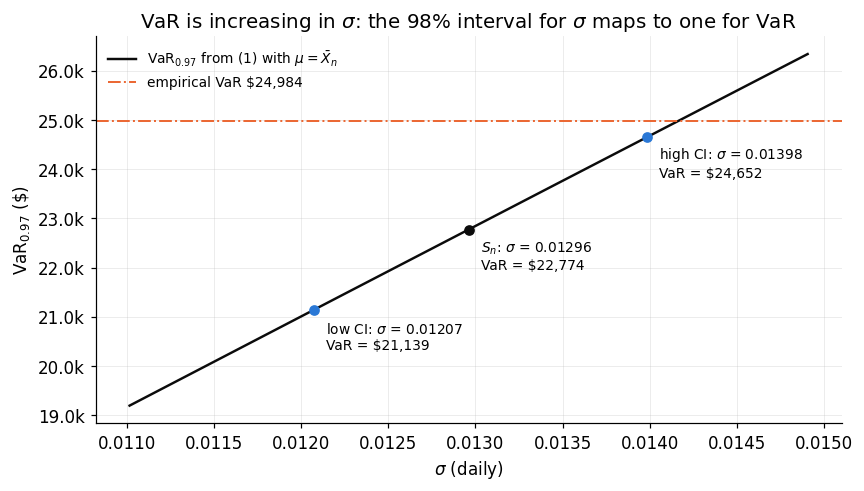

saved var_ci_simulation.png and var_ci_sigma.png


In [8]:
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.hist(Y, bins=180, density=True, color=C_B, alpha=0.25, lw=0)
ax.hist(Y, bins=180, density=True, histtype="step", color=C_B, lw=1.4,
        label=rf"(b) simulated $Y_m$, $M$ = {M_SIM:,}")
ymax = ax.get_ylim()[1] * 1.05; ax.set_ylim(0, ymax)
ax.axvspan(*CI_B, color=C_B, alpha=0.06, lw=0)
for v, ls in ((CI_B[0], "--"), (CI_B[1], "--")):
    ax.axvline(v, color=C_B, lw=1.3, ls=ls)
for v in CI_A:
    ax.axvline(v, color=C_A, lw=1.6, ls=":")
ax.axvline(VAR_TH, color=C_A, lw=1.8, label=f"(a) formula with $\\bar X_n, S_n$: {usd(VAR_TH)}")
ax.axvline(Y_BAR, color=C_B, lw=1.8, label=rf"(b) $\bar Y_M$: {usd(Y_BAR)}")
ax.axvline(VAR_EMP, color=C_EMP, lw=1.8, ls="-.", label=f"(a) empirical: {usd(VAR_EMP)}")
ax.plot([], [], color=C_A, ls=":", lw=1.6, label=f"(a) 98% CI, $\\mu$ known: [{usd(CI_A[0])}, {usd(CI_A[1])}]")
ax.plot([], [], color=C_B, ls="--", lw=1.3, label=f"(b) 98% CI (A, B): [{usd(CI_B[0])}, {usd(CI_B[1])}]")
ax.set_xlabel(r"one-day VaR$_{0.97}$ of the full loss (\$)"); ax.set_ylabel("density"); ax.set_yticks([])
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1000:,.1f}k"))
ax.set_title("Uncertainty in the 97% VaR from estimating the parameters")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9)
fig.tight_layout(); fig.savefig(FIG1, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.6))
sg = np.linspace(0.85 * S, 1.15 * S, 200)
ax.plot(sg, var_normal(XBAR, sg), color=C_INK, lw=1.6, label=r"VaR$_{0.97}$ from (1) with $\mu=\bar X_n$")
for s_, lab, col in ((SIG_LOW, "low CI", C_A), (S, "$S_n$", C_INK), (SIG_HIGH, "high CI", C_A)):
    ax.plot(s_, var_normal(XBAR, s_), "o", color=col, ms=6, zorder=5)
    ax.annotate(f"{lab}: $\\sigma$ = {s_:.5f}\nVaR = {usd(var_normal(XBAR, s_))}", (s_, var_normal(XBAR, s_)),
                textcoords="offset points", xytext=(8, -26), ha="left", fontsize=9)
ax.axhline(VAR_EMP, color=C_EMP, lw=1.3, ls="-.", label=f"empirical VaR {usd(VAR_EMP)}")
ax.set_xlabel(r"$\sigma$ (daily)"); ax.set_ylabel(r"VaR$_{0.97}$ (\$)")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1000:,.1f}k"))
ax.set_title(r"VaR is increasing in $\sigma$: the 98% interval for $\sigma$ maps to one for VaR")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG2, bbox_inches="tight"); plt.show()
print(f"saved {FIG1} and {FIG2}")

---
## 9. All numbers for the written PDF

In [9]:
line = "=" * 78
print(line); print("SUMMARY OF RESULTS"); print(line)
print(f"[DATA]  {len(prices)} closes, n = {n} returns;  X_bar = {XBAR:.8f};  S_n^2 = {S2:.10f};  S_n = {S:.8f}")
print(f"[(a1)]  empirical VaR = l_({J_EMP}) = {VAR_EMP:,.4f}")
print(f"[(a2)]  formula VaR = {VAR_TH:,.4f};  Phi^-1(0.03) = {Z_LO:.6f};  exponent {XBAR + S * Z_LO:.8f}")
print(f"[(a)CI] q_0.01 = {Q_LO:.6f}, q_0.99 = {Q_HI:.6f};  sigma in [{SIG_LOW:.8f}, {SIG_HIGH:.8f}];  "
      f"VaR in [{CI_A[0]:,.4f}, {CI_A[1]:,.4f}]")
print(f"[(b)]   Y_bar = {Y_BAR:,.4f} (s.e. {Y_SE:.2f});  A = Y_({J_A}) = {CI_B[0]:,.4f};  B = Y_({J_B}) = {CI_B[1]:,.4f}")

SUMMARY OF RESULTS
[DATA]  504 closes, n = 503 returns;  X_bar = 0.00134095;  S_n^2 = 0.0001679993;  S_n = 0.01296145
[(a1)]  empirical VaR = l_(488) = 24,984.3988
[(a2)]  formula VaR = 22,773.5495;  Phi^-1(0.03) = -1.880794;  exponent -0.02303687
[(a)CI] q_0.01 = 431.240537, q_0.99 = 578.639827;  sigma in [0.01207262, 0.01398446];  VaR in [21,138.5350, 24,651.9927]
[(b)]   Y_bar = 22,808.7652 (s.e. 2.67);  A = Y_(1250) = 20,697.3977;  B = Y_(123750) = 25,091.1601


---
## 10. Self-checks

In [10]:
checks = []
check = lambda name, ok: checks.append((name, bool(ok)))

check("dates and sample: first/last close as specified", str(prices.index[0].date()) == FIRST_DAY
      and str(prices.index[-1].date()) == LAST_DAY and n == len(prices) - 1)
check("formula (1) agrees with the normal quantile of the loss",
      np.isclose(VAR_TH, -V_PORT * np.expm1(norm.ppf(1 - ALPHA, XBAR, S))))
check("VaR is increasing in sigma", np.all(np.diff(var_normal(XBAR, np.linspace(0.5 * S, 2 * S, 50))) > 0))
check("chi-square quantiles: P(q_lo <= chi2 <= q_hi) = 1 - beta",
      np.isclose(chi2.cdf(Q_HI, n - 1) - chi2.cdf(Q_LO, n - 1), 1 - BETA))
check("sigma interval contains S_n and the VaR interval contains the point estimate",
      SIG_LOW < S < SIG_HIGH and CI_A[0] < VAR_TH < CI_A[1])
# coverage of the (a) interval: simulate many samples of n normal returns with known sigma
r2 = np.random.default_rng(SEED + 1)
sims = r2.normal(XBAR, S, size=(4_000, n))
s_sim = sims.std(axis=1, ddof=1)
lo_s, hi_s = s_sim * np.sqrt((n - 1) / Q_HI), s_sim * np.sqrt((n - 1) / Q_LO)
cover = np.mean((lo_s <= S) & (S <= hi_s))
check(f"the sigma interval covers the true sigma about 98% of the time (simulated: {cover:.3f})", abs(cover - 0.98) < 0.01)
check("simulation with mu fixed reproduces the analytic (a) interval to within 0.5%",
      abs(CI_SIG_SIM[0] / CI_A[0] - 1) < 0.005 and abs(CI_SIG_SIM[1] / CI_A[1] - 1) < 0.005)
check("quantile indices: A = Y_(1250), B = Y_(123750)", J_A == 1250 and J_B == 123_750)
check("(b) interval contains Y_bar and is wider than the (a) interval",
      CI_B[0] < Y_BAR < CI_B[1] and CI_B[1] - CI_B[0] > CI_A[1] - CI_A[0])
check("simulated mu_m spread matches S_n / sqrt(n) (within 2%)", abs(MU_M.std() / (S / np.sqrt(n)) - 1) < 0.02)
check("figures written", FIG1.exists() and FIG2.exists())

for nm, ok in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}]  {nm}")
assert all(ok for _, ok in checks), "some checks failed"
print("\nALL CHECKS PASSED")

  [PASS]  dates and sample: first/last close as specified
  [PASS]  formula (1) agrees with the normal quantile of the loss
  [PASS]  VaR is increasing in sigma
  [PASS]  chi-square quantiles: P(q_lo <= chi2 <= q_hi) = 1 - beta
  [PASS]  sigma interval contains S_n and the VaR interval contains the point estimate
  [PASS]  the sigma interval covers the true sigma about 98% of the time (simulated: 0.978)
  [PASS]  simulation with mu fixed reproduces the analytic (a) interval to within 0.5%
  [PASS]  quantile indices: A = Y_(1250), B = Y_(123750)
  [PASS]  (b) interval contains Y_bar and is wider than the (a) interval
  [PASS]  simulated mu_m spread matches S_n / sqrt(n) (within 2%)
  [PASS]  figures written

ALL CHECKS PASSED
